In [22]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [23]:
def f(x):
    return 3*x**2 -4*x +5

In [24]:
f(3.0)

20.0

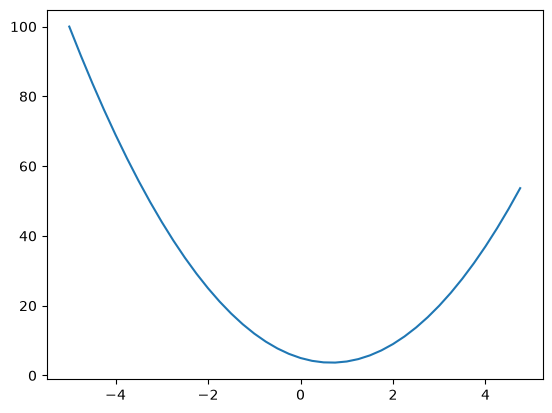

In [25]:
xs = np.arange(-5,5,0.25)

ys = f(xs)

plt.plot(xs, ys)

In [26]:
h = 0.0000001
x = 2/3
(f(x+h) -f(x))/h

2.9753977059954195e-07

In [27]:
a = 2.0
b= -3.0
c = 10.0
d = a*b +c
print(d)

4.0


In [28]:
h = 0.0001 

#inputs
a = 2.0
b= -3.0
c = 10.0

d1 = a*b +c

c += h
d2 = a*b + c

print('d1',d1)
print('d2',d2)

print('slope', (d2-d1)/h)





d1 4.0
d2 4.0001
slope 0.9999999999976694


In [29]:
class Value:
    def __init__(self, data, _children=(), _op=(''), label=''):
        self.data = data
        self.grad =0 #derivative of f for the output, respect to this variable
        self._prev = set(_children)
        self._backward = lambda: None
        self._op = _op
        self.label = label
    def __repr__(self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data + other.data, (self,other),'+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward


        return out
    
    def __mul__(self, other):
        other = other if isinstance(other,Value) else Value(other)

        out = Value(self.data * other.data, (self,other),'*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    def tanh(self):
        n = self.data
        t = (math.exp(2*n)-1)/(math.exp(2*n)+1)
        out = Value(t,(self,),'tanh')
        def _backward():
            self.grad += (1- t**2) * out.grad
        out._backward = _backward
        return out
    def backward(self):
        self.grad = 1.0
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        for node in reversed(topo):
            node._backward()
    
    def __rmul__(self,other):#other * self
        return self * other

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out
    
    def __pow__(self,other):
        assert isinstance(other,(int,float)), "only supports ints and floats"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other-1)) * out.grad
        out._backward = _backward
        return out
    
    def __truediv__(self,other):
        return self * (other**-1)
    
    def __neg__(self):
        return self * -1
    def __sub__(self,other):
        return self + (- other)
    def __radd__(self, other):   # other + self
        return self + other



    

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e= a*b; e.label='e'
d= e +c; d.label='d'
f = Value(-2.0, label='f')

L = d*f; L.label='L'
L


#(a.__mul__(b)).__add__(c)

d




Value(data=4.0)

In [30]:
a = Value(2.0)
b = Value(4.0)

a - b


Value(data=-2.0)

In [31]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [32]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{%s | data %.4f | grad %.4f}" % (n.label,n.data,n.grad ), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

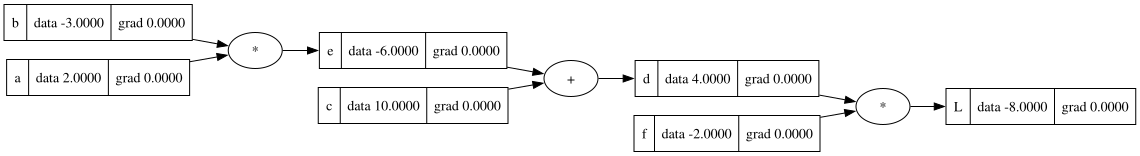

In [33]:
draw_dot(L)

In [34]:
a.data += 0.01*a.grad
b.data += 0.01*b.grad
c.data += 0.01*c.grad
f.data += 0.01*f.grad

#If we nudge in direction of the gradient, we expect a positive efefct on L

e = a*b
d = e+c
L = d*f

print(L.data)


-36.0


In [35]:
a.grad =-2.0 * -3.0
b.grad = -2.0 *2.0

In [36]:
e.grad = -2 * 1
c.grad = -2 * 1


In [37]:
#dd/dc = 1
# d = c+e

#dd/de = 1, we call this the local derivative (doesn't know about rest of the graph)
# d = c+e

#(f(g(x)))' = f'(g)*g' chain rule. here L = prod(sum(x))
#that is: dz/dx = dz/dy * dy/dx

dL/dc = dL/dd * dd/dc


e = a*b
de/da = b
de/db = a

dL/db = dL/de * de/db = -2 * -3 = 6

dL/da = dL/de * de/da = -2 *2 = -4




SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (4017105262.py, line 10)

In [ ]:
L = d * f

#dL/dd = f
#dL/df = d



In [ ]:
L.grad =1

#the plus node.. der are one, so the derivative just gets routed

In [ ]:
f.grad = 4 #d
d.grad = -2 #f


In [ ]:
def temp():
    h=0.0001
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e= a*b; e.label='e'
    d= e +c; d.label='d'
    f = Value(-2.0, label='f')

    L1 = d*f; L1.label='L'

    a = Value(2.0 , label='a')#so its df(x)/da
    b = Value(-3.0+h, label='b')
    c = Value(10.0 , label='c')
    e= a*b; e.label='e'
    d= e +c; d.label='d'
    
    f = Value(-2.0, label='f')

    L2 = d*f; L2.label='L'

    print((L2.data-L1.data)/h)

temp()


-4.000000000008441


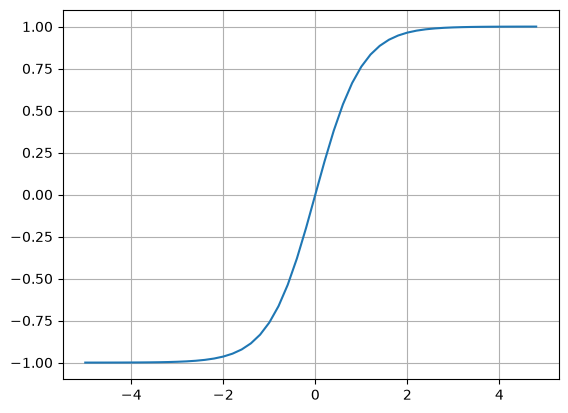

In [ ]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid()

In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'#cell body raw activation


o = n.tanh(); o.label = 'o'
#I implement tanh in my Value class

#now we try to find der of o, for the single weigths



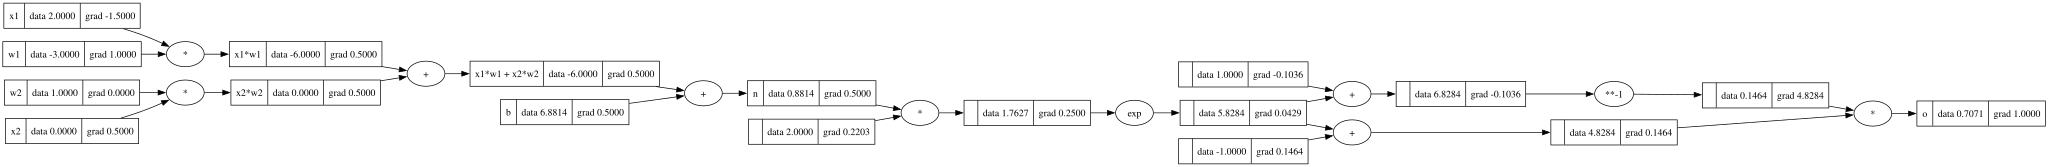

In [ ]:
draw_dot(o)

In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'#cell body raw activation


e = (2*n).exp()
o = (e-1)/ (e+1)


o.label = 'o'
#I implement tanh in my Value class

#now we try to find der of o, for the single weigths



In [ ]:
o.backward()

In [ ]:
o.grad = 1.0
o._backward()


In [ ]:
n._backward()

In [ ]:
b._backward()
x1w1x2w2._backward()
x2w2._backward()
x1w1._backward()


In [ ]:
w1.grad = x1.data * x1w1.grad
x1.grad = w1.data * x1w1.grad

x2.grad = w2.data * x2w2.grad #w2* do/dx2w2
w2.grad = x2.data * x2w2.grad 

In [ ]:
x1w1.grad = 0.5
x2w2.grad = 0.5

In [ ]:
x1w1x2w2.grad = 0.5
b.grad = 0.5

In [ ]:
n.grad = 0.5

In [ ]:
o.grad = 1.0

In [ ]:
1- o.data**2

0.4999999999999999

In [ ]:
#o = tanh(n)
#do/dn = 1 - tanh(n) **2 = 1 - o**2

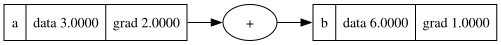

In [ ]:
a = Value(3.0, label='a')
b = a + a; b.label ='b'
b.backward()
draw_dot(b)

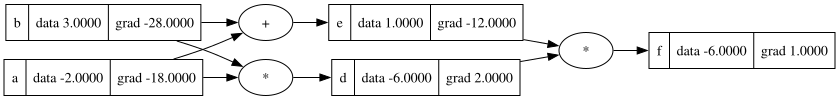

In [ ]:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')
d = a * b    ; d.label = 'd'
e = a + b    ; e.label = 'e'
f = d * e    ; f.label = 'f'

f.backward()

draw_dot(f)

#use generalization for multivariable case

In [ ]:
#With pytorch

import torch
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [ ]:
torch.Tensor([2.0]).double()
#since we are using tensors, things are more efficient and 
#we can do more operations in parallel

tensor([2.], dtype=torch.float64)

In [ ]:
#neural nets are just a specific class of mathematical expressions
#I'll make one that 
import random

In [144]:
class Neuron:
    def __init__(self,nin):#number of inputs 
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))#trigger happyness

    def __call__(self, x):
        #w*x + b
        act= sum((wi*xi for wi,xi in zip(self.w, x)),self.b) #overate over the tuples
        out = act.tanh()
        return out
    
    def parameters(self):
        return self.w + [self.b]
    


class Layer:
    def __init__(self,nin,nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs

    def parameters(self):
        #return [p for neuron in self.neurons for p in neuron.parameters()]
        params = []
        for neuron in self.neurons:
            ps = neuron.parameters()
            params.extend(ps)
        return params


class MLP:#multi layer perceptron
    def __init__(self,nin, nouts):#these are lists
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]



x = [2.0, 3.0, -1.0]
n = MLP(3,[4,4,1])
n(x)
        

Value(data=0.7971652923100606)

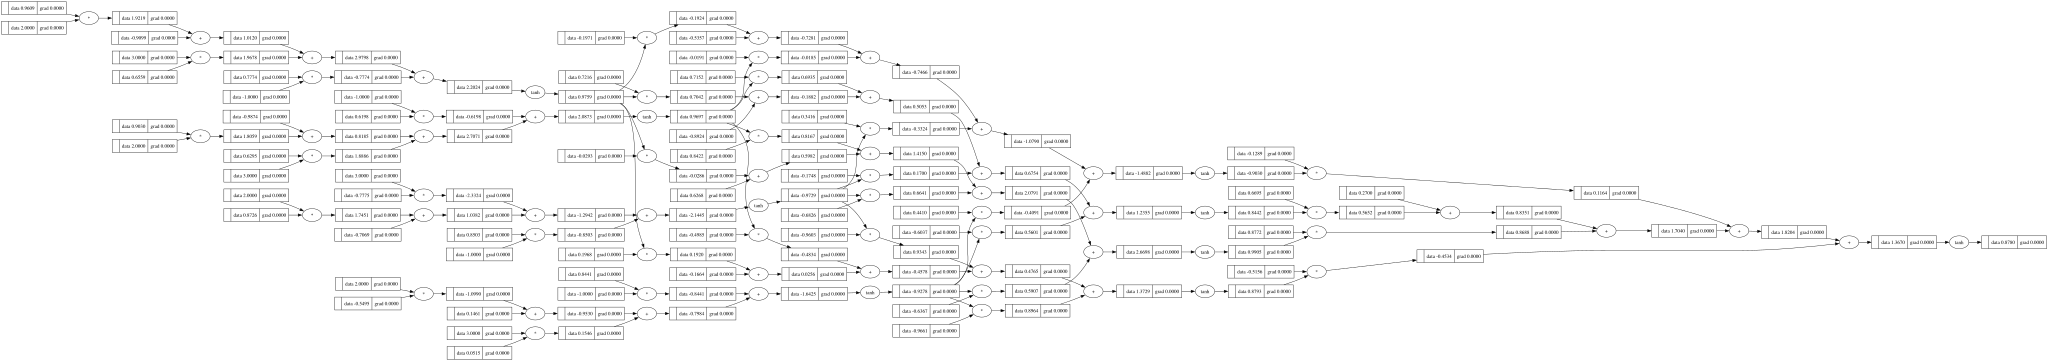

In [64]:
draw_dot(n(x))

In [143]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets
#basically a binary classifier

#how do we tune the weights to get the desired target?
#We use the loss, it measures how well the nt is performing

In [139]:
#We are gonna use,  mean square errors loss
#We want to minimize the loss
ypred = [n(x) for x in xs]

loss = sum([(yout - ygt)**2 for ygt,yout in zip(ys,ypred)])
loss
#if loss is low, every prediction is close to its target

Value(data=0.002073755854772155)

In [140]:
loss.backward()


In [ ]:
n.parameters()#these are the grad of the initial parameters and weights
#since we assume that the input cannot be changed. We change the weights
len(n.parameters())



41

In [138]:
for p in n.parameters():#gradient descent, vector pointing direction of increased loss
    p.data += -0.01 * p.grad
    #not too big, to not overstep

#forward pass, backward pass, update

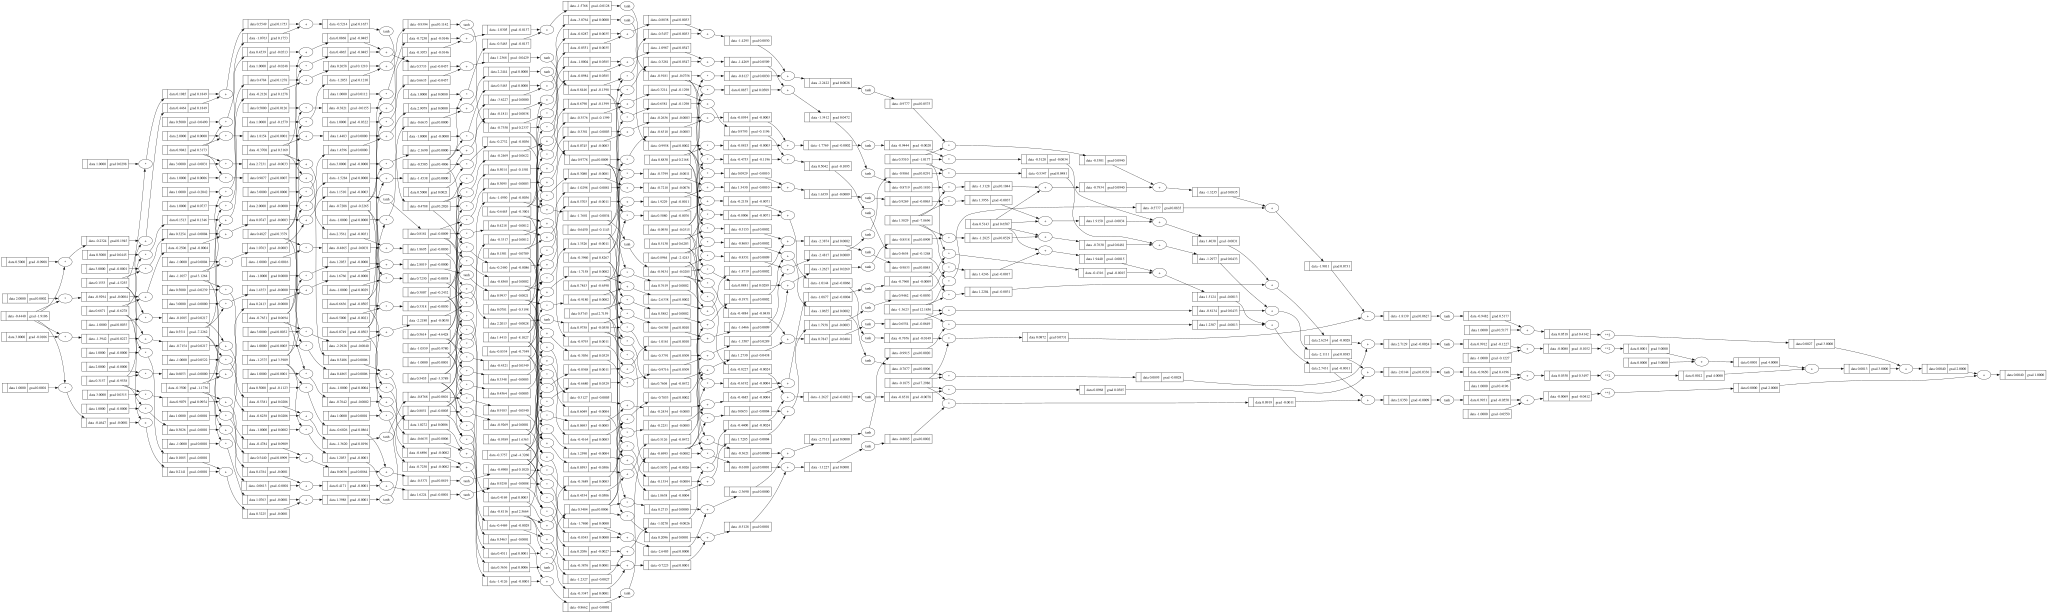

In [137]:
draw_dot(loss)


In [156]:
for k in range(2000):
    
    #forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt,yout in zip(ys,ypred)])

    #backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    #update
    for p in n.parameters():
        p.data += -0.1 * p.grad
    print(k,loss.data)

0 3.9091676885037715e-06
1 3.909092405461358e-06
2 3.9090171253306405e-06
3 3.9089418481113215e-06
4 3.908866573803101e-06
5 3.9087913024049476e-06
6 3.908716033918504e-06
7 3.90864076834153e-06
8 3.908565505675225e-06
9 3.908490245918279e-06
10 3.908414989072155e-06
11 3.908339735134749e-06
12 3.90826448410757e-06
13 3.908189235989788e-06
14 3.908113990780666e-06
15 3.908038748480816e-06
16 3.907963509090117e-06
17 3.907888272608463e-06
18 3.907813039034699e-06
19 3.9077378083692824e-06
20 3.907662580613156e-06
21 3.90758735576381e-06
22 3.907512133822926e-06
23 3.9074369147894295e-06
24 3.907361698663267e-06
25 3.907286485444853e-06
26 3.907211275133763e-06
27 3.907136067729827e-06
28 3.907060863231398e-06
29 3.906985661641474e-06
30 3.906910462957293e-06
31 3.906835267178949e-06
32 3.906760074307566e-06
33 3.906684884341839e-06
34 3.906609697281861e-06
35 3.906534513127514e-06
36 3.906459331878671e-06
37 3.906384153535719e-06
38 3.9063089780978776e-06
39 3.906233805564229e-06
40 3.9